In [1]:
import tensorflow as tf
from tensorflow import keras
import keras.activations
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
print(tf.__version__)
fashion_mnist = tf.keras.datasets.fashion_mnist
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()
clothes = ['T-shirt or another top', 'Pants', 'Pullover', 'Dress', 'Jacket', 'Sandal or Heels', 'Shirt', 'Sneaker', 'Bag','Boot']
train_images = train_images / 255.0
test_images = test_images / 255.0
train_images=train_images[:50000] #Optimized by using fewer images, but decreased accuracies
train_labels=train_labels[:50000]

train_images = np.expand_dims(train_images, -1)
test_images = np.expand_dims(test_images, -1)

2.21.0


In [2]:
n_layers = 10
n_epochs =10
print(f"CONFIG layers={n_layers} neurons=128 epochs={n_epochs} batch_size=128")
activations = {"ReLU": "relu", "Sigmoid": "sigmoid", "tanh": keras.activations.tanh,"LeakyReLU": tf.nn.leaky_relu, "Gelu" : "gelu"} #Dictionary of these functions to add more functions in the future
seeds = [1, 2, 3]
results = {}
for name, act in activations.items():
    print("\nActivation function of the currently trained model: ", name)
    results[name] = []
    for seed in seeds:
        keras.utils.set_random_seed(seed)
        model = keras.Sequential(
            [keras.layers.Flatten(input_shape=(28,28))] +
            [keras.layers.Dense(128, activation=act) for _ in range(n_layers)] +
            [keras.layers.Dense(10)]
        )

        model.compile(optimizer='adam', loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])
        model.fit(train_images, train_labels, epochs=n_epochs, verbose=2, batch_size = 128, validation_data=(test_images, test_labels))
        test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=0)
        results[name].append(test_acc)
        print(name, seed, test_acc)

CONFIG layers=10 neurons=128 epochs=10 batch_size=128

Activation function of the currently trained model:  ReLU


C:\Users\levku\tf-env\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
391/391 - 4s - 9ms/step - accuracy: 0.7560 - loss: 0.6646 - val_accuracy: 0.8343 - val_loss: 0.4630
Epoch 2/10
391/391 - 3s - 8ms/step - accuracy: 0.8503 - loss: 0.4171 - val_accuracy: 0.8479 - val_loss: 0.4305
Epoch 3/10
391/391 - 3s - 8ms/step - accuracy: 0.8675 - loss: 0.3680 - val_accuracy: 0.8498 - val_loss: 0.4145
Epoch 4/10
391/391 - 2s - 4ms/step - accuracy: 0.8765 - loss: 0.3444 - val_accuracy: 0.8589 - val_loss: 0.3897
Epoch 5/10
391/391 - 2s - 5ms/step - accuracy: 0.8829 - loss: 0.3273 - val_accuracy: 0.8631 - val_loss: 0.3852
Epoch 6/10
391/391 - 3s - 8ms/step - accuracy: 0.8869 - loss: 0.3112 - val_accuracy: 0.8649 - val_loss: 0.3747
Epoch 7/10
391/391 - 3s - 7ms/step - accuracy: 0.8911 - loss: 0.2956 - val_accuracy: 0.8749 - val_loss: 0.3742
Epoch 8/10
391/391 - 3s - 7ms/step - accuracy: 0.8959 - loss: 0.2881 - val_accuracy: 0.8689 - val_loss: 0.3819
Epoch 9/10
391/391 - 3s - 7ms/step - accuracy: 0.8967 - loss: 0.2838 - val_accuracy: 0.8703 - val_loss: 0.3797
E

In [3]:
means = []
stds = []
model_names = []
for name, accs in results.items():
    model_names.append(name)
    means.append(np.mean(accs))
    stds.append(np.std(accs, ddof=1))
    print(f"{name}: Mean of accuracies: {means[-1]:.4f} Standard deviations: {stds[-1]:.4f}")
mean_of_means = np.mean(means)
median_of_means = np.median(means)
std_between_models = np.std(means)

ReLU: Mean of accuracies: 0.8751 Standard deviations: 0.0010
Sigmoid: Mean of accuracies: 0.1993 Standard deviations: 0.0004
tanh: Mean of accuracies: 0.8640 Standard deviations: 0.0038
LeakyReLU: Mean of accuracies: 0.8668 Standard deviations: 0.0049
Gelu: Mean of accuracies: 0.8653 Standard deviations: 0.0008



 Statistics of activation functions (accuracy)
Mean of accuracies: 0.7341
Median of accuracies: 0.8653
Standard Deviation of accuracies: 0.2674


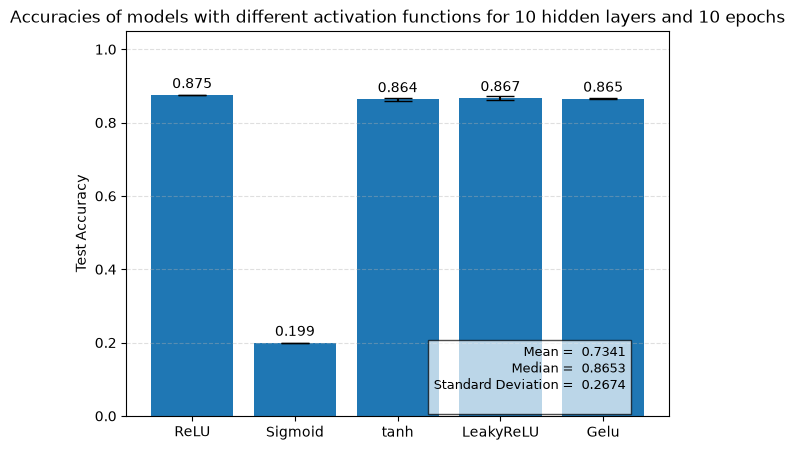

In [4]:
print("\n Statistics of activation functions (accuracy)")
print(f"Mean of accuracies: {mean_of_means:.4f}")
print(f"Median of accuracies: {median_of_means:.4f}")
print(f"Standard Deviation of accuracies: {std_between_models:.4f}")

plt.figure(figsize=(7,5))
plt.bar(model_names, means, yerr=[stds], capsize=10)
plt.ylim(0,1.05)
plt.ylabel("Test Accuracy")
plt.title(f"Accuracies of models with different activation functions for {n_layers} hidden layers and {n_epochs} epochs")
stats_text = (
    f"Mean = {mean_of_means: .4f}\n"
    f"Median = {median_of_means: .4f}\n"
    f"Standard Deviation = {std_between_models: .4f}\n"
)
for i, v in enumerate(means):
    plt.text(i, v + 0.01, f"{v:.3f}", ha ='center', va='bottom')
ax = plt.gca()
ax.text(
0.92,0.02,
stats_text,
transform=ax.transAxes,
ha='right',
va='bottom',
fontsize=9,
bbox=dict(facecolor='white',alpha=0.7))
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.savefig(f"figures/fmnist_{n_layers}layers_{n_epochs}epochs.png", dpi=150, bbox_inches="tight")
plt.show()

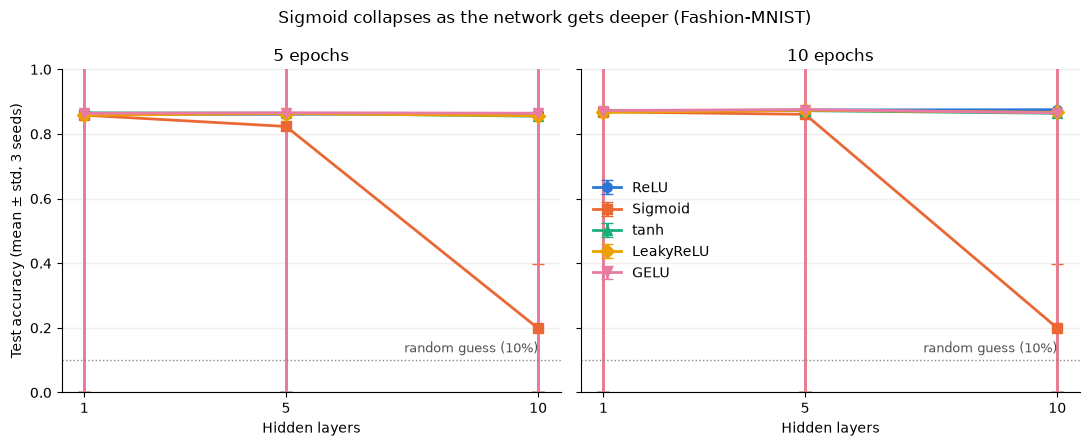

In [5]:
df = pd.read_csv("results/summary.csv")

acts    = ["ReLU", "Sigmoid", "tanh", "LeakyReLU", "GELU"]
colors  = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
markers = ["o", "s", "^", "D", "v"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, n_ep in zip(axes, [5, 10]):
    for act, c, m in zip(acts, colors, markers):
        d = df[(df["activation"] == act) & (df["epochs"] == n_ep)].sort_values("layers")
        ax.errorbar(d["layers"], d["mean"], yerr=d["std"], label=act, color=c,
                    marker=m, markersize=7, linewidth=2, capsize=4)
    ax.axhline(0.10, color="#8a8984", linewidth=1, linestyle=":")
    ax.text(10, 0.115, "random guess (10%)", ha="right", va="bottom", fontsize=9, color="#52514e")
    ax.set_title(f"{n_ep} epochs")
    ax.set_xlabel("Hidden layers")
    ax.set_xticks([1, 5, 10])
    ax.set_ylim(0, 1)
    ax.grid(axis="y", color="#f0efec", linewidth=1)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Test accuracy (mean ± std, 3 seeds)")
axes[1].legend(loc="center left", frameon=False)
fig.suptitle("Sigmoid collapses as the network gets deeper (Fashion-MNIST)")
fig.tight_layout()
fig.savefig("figures/accuracy_vs_depth.png", dpi=150, bbox_inches="tight")
plt.show()